In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import japanize_matplotlib  # 日本語フォントの設定

In [2]:
#!pip install japanize-matplotlib

In [3]:
import gymnasium as gym # gymnasium を gym という名前でインポート
from gymnasium import spaces
import numpy as np
import time
import warnings 

class SimplifiedTaskJITAIEnv(gym.Env):
    metadata = {'render_modes': ['human', 'rgb_array'], 'render_fps': 4} # rgb_arrayも追加しておくと良い

    def __init__(self,
                 n_actions=3,
                 max_episode_length=90,
                 seed=0,
                 co_score=0.5,
                 total_task_work=230.0,
                 delta_d_base=0.02,
                 epsilon_d_base=0.05,
                 D_threshold_base=0.2,
                 d_increase_on_inaction_base=0.002,
                 co_effect_on_d_increase_inaction_multiplier=-0.5,
                 inaction_steps_threshold=5,
                 base_prob_start_action_base=0.6,
                 intervention_boost_to_prob_start_base=[0.0, 0.1, 0.25],
                 urgency_factor_base=0.3,
                 mu_s_base=4.1,
                 rho1_base=2.0,
                 rho2_base=5.0,
                 co_effect_on_delta_d_multiplier=0.3,
                 co_effect_on_epsilon_d_multiplier=0.5,
                 co_effect_on_D_threshold_multiplier=1.5,
                 co_effect_on_base_prob_start_multiplier=0.2,
                 co_effect_on_intervention_boost_multiplier=0.1,
                 co_effect_on_urgency_factor_multiplier=-0.4,
                 co_effect_on_mu_s_multiplier=0.2,
                 co_effect_on_rho1_multiplier=0.1,
                 co_effect_on_rho2_multiplier=0.1,
                 init_d=0.1,
                 chosen_obs_names=['D', 'S', 'TP', 'CO', 'TR', 'T_parity'],
                 n_version=0,
                 s_noise_std_base=0.0,
                 co_effect_on_s_noise_std_multiplier=0.0,
                 intervention_cost=0.1,
                 # ★★★ ここに新しい引数を追加します ★★★
                 habituation_increment_weak=0.02,
                 habituation_increment_strong=0.05,
                 habituation_decay=0.01,
                 render_mode=None): # <<-- render_mode 引数を追加
        super().__init__()

        self.max_episode_length = max_episode_length
        self.n_actions = n_actions
        self.chosen_obs_names = chosen_obs_names
        self.n_version = n_version

        self.co_score = np.clip(co_score, 0.0, 1.0)
        self.current_CO = self.co_score # __init__ で一度設定

        self.delta_d_base = delta_d_base
        self.epsilon_d_base = epsilon_d_base
        self.D_threshold_base = D_threshold_base
        self.d_increase_on_inaction_base = d_increase_on_inaction_base
        self.co_effect_on_d_increase_inaction_multiplier = co_effect_on_d_increase_inaction_multiplier
        self.inaction_steps_threshold = inaction_steps_threshold

        self.base_prob_start_action_base = base_prob_start_action_base
        self.intervention_boost_to_prob_start_base = np.array(intervention_boost_to_prob_start_base)
        if len(self.intervention_boost_to_prob_start_base) != n_actions:
            raise ValueError("Length of intervention_boost_to_prob_start_base must match n_actions.")
        self.urgency_factor_base = urgency_factor_base
        self.mu_s_base = mu_s_base
        self.rho1_base = rho1_base
        self.rho2_base = rho2_base
        self.total_task_work = total_task_work
        self.s_noise_std_base = s_noise_std_base

        self.co_effect_on_delta_d_multiplier = co_effect_on_delta_d_multiplier
        self.co_effect_on_epsilon_d_multiplier = co_effect_on_epsilon_d_multiplier
        self.co_effect_on_D_threshold_multiplier = co_effect_on_D_threshold_multiplier
        self.co_effect_on_base_prob_start_multiplier = co_effect_on_base_prob_start_multiplier
        self.co_effect_on_intervention_boost_multiplier = co_effect_on_intervention_boost_multiplier
        self.co_effect_on_urgency_factor_multiplier = co_effect_on_urgency_factor_multiplier
        self.co_effect_on_mu_s_multiplier = co_effect_on_mu_s_multiplier
        self.co_effect_on_rho1_multiplier = co_effect_on_rho1_multiplier
        self.co_effect_on_rho2_multiplier = co_effect_on_rho2_multiplier
        self.co_effect_on_s_noise_std_multiplier = co_effect_on_s_noise_std_multiplier

        self.init_d = init_d
        self.init_s = 0.0
        self.init_task_progress = 0.0
        
        self.intervention_cost = intervention_cost

        # ★★★【修正箇所】この位置に「介入慣れ」のパラメータ定義を移動してくる ★★★
        # --- 介入慣れ (Habituation) 用のパラメータと状態変数を追加 ---
        self.habituation_level = 0.0 # 現在の慣れレベル (0.0から1.0)
        
        self.habituation_decay = 0.01   # 1ステップあたりの慣れ減少量 (非介入時)
        self.max_habituation_level = 1.0  # 慣れレベルの上限
        # --- ここまで移動 ---
# ↓↓↓ 古い self.habituation_increment の行を、以下の2行に置き換える ↓↓↓
        # self.habituation_increment = 0.05 # ← この行を削除またはコメントアウト
        self.habituation_increment_weak = habituation_increment_weak     # 弱い介入での慣れ増加量
        self.habituation_increment_strong = habituation_increment_strong   # 強い介入での慣れ増加量

        self.seed = seed # 初期シード
        self.rng1 = np.random.default_rng(self.seed) # __init__で一度初期化

        self.current_t = 0
        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.consecutive_inaction_steps = 0

        self.action_space = spaces.Discrete(self.n_actions)
        min_obs_values, max_obs_values = self.extract_min_max()
        self.observation_space = spaces.Box(
            low=np.array(min_obs_values, dtype=np.float32),
            high=np.array(max_obs_values, dtype=np.float32),
            dtype=np.float32
        )
        self._initialize_operational_params() # 初期パラメータ設定

        # --- レンダリングモード設定 ---
        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        # --- ここまで ---

        # --- レンダリング用に直前の情報を保持する変数 (適宜追加) ---
        self.last_agent_action = None # agent_action を保持
        self.last_step_reward = 0.0
        # --- ここまで ---


    def _initialize_operational_params(self):
        # このメソッドは reset で呼ばれるため、co_score に応じた調整は reset で行う
        self.delta_d, self.epsilon_d, self.D_threshold = 0.0, 0.0, 0.0
        self.base_prob_start_action = 0.0
        self.intervention_boost_to_prob_start = np.zeros(self.n_actions)
        self.urgency_factor = 0.0
        self.mu_s, self.rho1, self.rho2 = 0.0, 0.0, 0.0
        self.s_noise_std = 0.0

    def _adjust_param(self, base_val, multiplier, co_factor):
        return base_val * (1 + co_factor * multiplier)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None: # 引数でseedが指定されたら、それを使用
            self.seed = seed
        # self.seed はインスタンスの初期seed、または引数で与えられたseed
        # rngの再初期化時は、エピソードごとに異なる状態にするため工夫が必要な場合もあるが、
        # Gymnasiumのsuper().reset(seed=seed)が内部で適切に処理してくれることを期待する。
        # ここでは、ユーザーの元のコードに合わせてrng1を再生成する
        self.rng1 = np.random.default_rng(self.seed) # self.seed を使う

        self._initialize_operational_params() # パラメータを一度リセット
        co_factor = self.co_score - 0.5 # co_score は __init__ で設定されたものを使用

        self.D_threshold = np.clip(self.D_threshold_base, 0.001, 0.999)
        
        self.delta_d = np.clip(self._adjust_param(self.delta_d_base, self.co_effect_on_delta_d_multiplier, co_factor), 0.0, 0.999)
        self.epsilon_d = np.clip(self._adjust_param(self.epsilon_d_base, self.co_effect_on_epsilon_d_multiplier, co_factor), 0.0, 0.999)

        self.base_prob_start_action = np.clip(self._adjust_param(self.base_prob_start_action_base, self.co_effect_on_base_prob_start_multiplier, co_factor), 0.01, 0.99)
        boost_adjustment = (1 + co_factor * self.co_effect_on_intervention_boost_multiplier)
        self.intervention_boost_to_prob_start = np.clip(self.intervention_boost_to_prob_start_base * boost_adjustment, 0.0, 0.5)
        self.urgency_factor = self._adjust_param(self.urgency_factor_base, self.co_effect_on_urgency_factor_multiplier, co_factor)
        self.urgency_factor = np.clip(self.urgency_factor, -0.5, 0.5) # 元のコードではマイナスもあり得る
        self.mu_s = np.clip(self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor), 0.1, None) # 下限0.1
        self.rho1 = np.clip(self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor), 0.0, None) # 下限0.0
        self.rho2 = np.clip(self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor), 0.0, None) # 下限0.0

        if self.n_version == 1:
            self.s_noise_std = np.clip(self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor), 0.0, None) # 下限0.0
        else:
            self.s_noise_std = 0.0

        self.D = self.init_d
        self.S = self.init_s
        self.TaskProgress = self.init_task_progress
        self.current_t = 0
        self.consecutive_inaction_steps = 0
        self.habituation_level = 0.0 # <<-- エピソード開始時に慣れレベルをリセット

        # レンダリング用変数のリセット
        self.last_agent_action = None
        self.last_step_reward = 0.0

        obs = self._get_observation()
        info = self._get_info() # 最初に基本情報を取得
        info.update({"message": "Environment reset."}) # メッセージを追加

        # reset時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()
            
        return obs, info

    def step(self, agent_action):
        a = int(agent_action)
         # --- ★介入慣れレベルの更新ロジックを追加★ ---
     
    # --- ★介入慣れレベルの更新ロジックを修正★ ---
        # if a == 1 or a == 2: ... else: ... の部分を以下に置き換える
        if a == 1: # 弱い介入が選択された場合
            self.habituation_level += self.habituation_increment_weak
        elif a == 2: # 強い介入が選択された場合
            self.habituation_level += self.habituation_increment_strong
        else: # 介入なし(行動0)が選択された場合
            self.habituation_level -= self.habituation_decay
        
        # 慣れレベルが 0.0 から上限値の範囲に収まるように調整
        self.habituation_level = np.clip(self.habituation_level, 0.0, self.max_habituation_level)
        # --- ここまで修正 ---


        if not (0 <= a < self.n_actions): # Action space validation
            raise ValueError(f"Action {a} is out of range for n_actions={self.n_actions}")

        self.last_agent_action = a # 直前の行動を保存

        task_progress_t = self.TaskProgress # ステップ開始時の進捗

        time_remaining_normalized = (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0
        urgency_effect_on_prob_start = 0.0
        urgency_threshold = 0.3 # この値はパラメータ化しても良い
        if time_remaining_normalized < urgency_threshold and time_remaining_normalized >= 0:
            urgency_level = 1.0 - (time_remaining_normalized / urgency_threshold)
            urgency_effect_on_prob_start = self.urgency_factor * urgency_level



        # --- ★介入慣れによる効果低減を計算★ ---
        effectiveness_multiplier = 1.0 - (self.habituation_level / self.max_habituation_level)
        
        actual_boost = self.intervention_boost_to_prob_start[a] * effectiveness_multiplier
        # 注意: 行動0のboostは元々0なので、この計算は実質的に介入行動(1, 2)にのみ影響

        

        prob_start_action_calculated = self.base_prob_start_action \
                                     + actual_boost \
                                     + urgency_effect_on_prob_start
        prob_start_action_calculated = np.clip(prob_start_action_calculated, 0.01, 0.99)






        s_this_step = 0.0
        action_started_this_step = False
        if self.rng1.random() < prob_start_action_calculated: # rng1を使用
            action_started_this_step = True
            s_next_mu_calculated = self.mu_s
            if a == 1: s_next_mu_calculated += self.rho1 # 行動タイプ1 (介入1と仮定)
            elif a == 2: s_next_mu_calculated += self.rho2 # 行動タイプ2 (介入2と仮定)
            # 注意: a==0 の場合は s_next_mu_calculated は self.mu_s のまま。これが意図通りか確認。
            
            s_final_next_if_started = s_next_mu_calculated
            if self.n_version == 1 and self.s_noise_std > 0:
                s_final_next_if_started = max(0.0, self.rng1.normal(s_next_mu_calculated, self.s_noise_std)) # rng1を使用
            s_this_step = max(0.0, s_final_next_if_started)
        self.S = s_this_step

        d_increased_this_step_due_to_inaction = 0.0 # 初期化
        if not action_started_this_step:
            self.consecutive_inaction_steps += 1
            if self.consecutive_inaction_steps >= self.inaction_steps_threshold: # 閾値以上でD増加
                co_factor = self.co_score - 0.5
                actual_d_increase = self._adjust_param(
                    self.d_increase_on_inaction_base,
                    self.co_effect_on_d_increase_inaction_multiplier,
                    co_factor
                )
                actual_d_increase = max(0, actual_d_increase) # 負の増加はしない
                self.D += actual_d_increase
                d_increased_this_step_due_to_inaction = actual_d_increase
        else:
            self.consecutive_inaction_steps = 0
        self.D = np.clip(self.D, 0.0, 1.0)


        if self.total_task_work > 1e-9: # ゼロ除算を避ける
            progress_this_step = self.S / self.total_task_work
            self.TaskProgress = np.clip(task_progress_t + progress_this_step, 0.0, 1.0)
        else: # total_task_work がほぼ0なら、Sが正なら即完了とみなすか、進捗なしとするか
            self.TaskProgress = 1.0 if self.S > 0 else task_progress_t


        step_reward = 0.0
        progress_made_in_step = self.TaskProgress - task_progress_t
        reward_scale_factor = 10.0 # パラメータ化しても良い
        step_reward += progress_made_in_step * reward_scale_factor
        
        task_completed_this_step = (task_progress_t < 1.0 and self.TaskProgress >= 1.0)
        if task_completed_this_step:
            step_reward += 50.0 # タスク完了ボーナス

        # 介入コスト (agent_action a が介入を示す場合)
        # 例えば a=1 (弱い介入), a=2 (強い介入) がコストを伴うと仮定。a=0はコストなし。
        if a == 1 or a == 2: # この条件は環境の行動定義に合わせる
            step_reward -= self.intervention_cost
        
        self.last_step_reward = step_reward # 直前の報酬を保存

        terminated = False
        truncated = False
        
        current_info = self._get_info() # 情報を先に取得
        current_info["action_taken"] = a # info に agent_action を含める
        current_info["action_started_this_step"] = action_started_this_step
        current_info["prob_start_action"] = prob_start_action_calculated
        current_info["urgency_effect_on_prob_start"] = urgency_effect_on_prob_start
        current_info["d_increased_due_to_inaction"] = d_increased_this_step_due_to_inaction
        current_info["task_completed_this_step"] = task_completed_this_step # このステップで完了したか


        if task_completed_this_step:
            terminated = True
            current_info['task_completed'] = True # Gymnasiumの info['TimeLimit.truncated'] と区別するため

        if self.D >= self.D_threshold and not terminated: # Dが閾値を超えたら終了 (タスク未完了の場合)
            terminated = True
            current_info['disengaged'] = True # 離脱を示すフラグ
            step_reward -= 20.0 # 離脱ペナルティ
            self.S = 0.0 # 行動量を0に (意図による)
        
        self.current_t += 1
        if self.current_t >= self.max_episode_length and not terminated: # 最大ステップ到達で打ち切り
            truncated = True
            current_info['TimeLimit.truncated'] = True # Gymnasium標準のキー
            if self.TaskProgress < 1.0: # 未完了ならペナルティ
                step_reward -= 10.0

        observation = self._get_observation()
        
        # step時に自動でrenderを呼び出す場合 (任意)
        # if self.render_mode == "human":
        #     self.render()

        return observation, float(step_reward), terminated, truncated, current_info

    def _get_observation(self):
        obs_dict = {
            'D': self.D, 'S': self.S, 'TP': self.TaskProgress, 'CO': self.current_CO,
            'TR': (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            'Habituation': self.habituation_level # <<-- ★追加
        }
        obs_values = []
        for obs_name in self.chosen_obs_names:
            if obs_name in obs_dict:
                obs_values.append(obs_dict[obs_name])
            elif obs_name == 'T_parity':
                obs_values.append(self.get_T_parity())
            else:
                obs_values.append(0.0) # 未知の観測名は0
                warnings.warn(f"Unknown obs_name '{obs_name}' in chosen_obs_names. Appending 0.0.", UserWarning)
        return np.array(obs_values, dtype=np.float32)

    def _get_info(self):
        # このメソッドは reset と step の両方から呼ばれるため、
        # step固有の情報（prob_start_actionなど）はstepメソッド内でcurrent_infoに追加する
        base_info = {
            "current_D": self.D, "current_S": self.S,
            "current_TaskProgress": self.TaskProgress, "current_CO": self.current_CO,
            "current_t": self.current_t,
            "time_remaining_normalized": (self.max_episode_length - self.current_t) / self.max_episode_length if self.max_episode_length > 0 else 0.0,
            "consecutive_inaction_steps": self.consecutive_inaction_steps,
            "adjusted_D_threshold": getattr(self, 'D_threshold', None),
            "current_Habituation": self.habituation_level, # <<-- ★この行を追加
            # resetで計算されるパラメータをinfoに含めたい場合、ここに追加
            "D_threshold_operational": self.D_threshold,
            "base_prob_start_action_operational": self.base_prob_start_action,
            # ... など
        }
        return base_info

    def extract_min_max(self):
        # このメソッドは複雑なため、ユーザー様の実装を信頼し、ここでは変更しません。
        # chosen_obs_names に合わせて min/max を正しく返すことが重要です。
        min_values = []; max_values = []
        co_factor_extrema = 0.5 # co_score が 0 または 1 の場合を想定 (0.5 - 0.5 = 0, 0.5 + 0.5 = 1)

        # mu_s の取りうる範囲を推定 (簡略化のため、rhoは最大のものだけ考慮)
        mu_s_adj_plus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, co_factor_extrema)
        mu_s_adj_minus = self._adjust_param(self.mu_s_base, self.co_effect_on_mu_s_multiplier, -co_factor_extrema)
        max_mu_s_base_adjusted = max(mu_s_adj_plus, mu_s_adj_minus, self.mu_s_base)
        
        rho1_adj_plus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, co_factor_extrema)
        rho1_adj_minus = self._adjust_param(self.rho1_base, self.co_effect_on_rho1_multiplier, -co_factor_extrema)
        max_rho1_adjusted = max(rho1_adj_plus, rho1_adj_minus, self.rho1_base)

        rho2_adj_plus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, co_factor_extrema)
        rho2_adj_minus = self._adjust_param(self.rho2_base, self.co_effect_on_rho2_multiplier, -co_factor_extrema)
        max_rho2_adjusted = max(rho2_adj_plus, rho2_adj_minus, self.rho2_base)

        max_s_component = max(0, max_mu_s_base_adjusted) + max(0, max_rho1_adjusted, max_rho2_adjusted) # 簡略化: mu_s + max(rho)

        s_noise_std_adj_plus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, co_factor_extrema) if self.n_version == 1 else 0.0
        s_noise_std_adj_minus = self._adjust_param(self.s_noise_std_base, self.co_effect_on_s_noise_std_multiplier, -co_factor_extrema) if self.n_version == 1 else 0.0
        max_s_noise_std_adj = max(0, s_noise_std_adj_plus, s_noise_std_adj_minus, self.s_noise_std_base if self.n_version == 1 else 0.0)

        # Sの最大値の推定 (ノイズも考慮)
        # 非常に大まかな推定: 平均的な最大値 + ノイズの数標準偏差分 (例: 3*std)
        # より正確には、s_next_mu_calculated と s_noise_std の関係から求める必要がある
        max_s_estimate = max(0.1, max_s_component + (3 * max_s_noise_std_adj if self.n_version == 1 else 0.0) )


        for check_obs in self.chosen_obs_names:
            if check_obs == 'D': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'S': min_values.append(0.0); max_values.append(max_s_estimate) # 推定値を使用
            elif check_obs == 'TP': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'CO': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'TR': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'T_parity': min_values.append(0.0); max_values.append(1.0)
            elif check_obs == 'Habituation': min_values.append(0.0); max_values.append(self.max_habituation_level) # <<-- ★追加
            else: raise ValueError(f"Unknown obs_name '{check_obs}' in chosen_obs_names for extract_min_max.")
        return min_values, max_values

    def get_T_parity(self):
        return float((self.current_t % 2) == 0) # 0.0 または 1.0

    def render(self):
        if self.render_mode == "human":
            print(f"\n--- Time: {self.current_t} / {self.max_episode_length} ---")
            print(f"  CO Score: {self.co_score:.2f}")
            if self.last_agent_action is not None:
                print(f"  Last Action Taken by Agent: {self.last_agent_action}")
            else:
                print("  Last Action Taken by Agent: None (Start of Episode)")
            print(f"  Last Reward Received: {self.last_step_reward:.3f}") # last_step_reward を参照
            print(f"  D: {self.D:.3f} (Threshold: {self.D_threshold:.3f})")
            print(f"  S: {self.S:.3f}")
            print(f"  TaskProgress (TP): {self.TaskProgress:.3f}")
            print(f"  Consecutive Inaction: {self.consecutive_inaction_steps}")
            print(f"  Habituation Level: {self.habituation_level:.3f}") # <<-- ★追加
            
            # 内部状態 (デバッグ用など)
            # print(f"  Prob Start Action: {getattr(self, 'prob_start_action_calculated', 'N/A')}") # step内で計算
            # print(f"  Action Started This Step: {getattr(self, 'action_started_this_step', 'N/A')}") # step内で計算
            
            # 終了状態の表示 (stepメソッドのterminated/truncatedロジックと整合させる)
            is_terminated = False
            is_truncated = False
            if getattr(self, 'task_completed_this_step', False) or (getattr(self, 'TaskProgress',0) >= 1.0): # stepメソッドでtask_completed_this_stepフラグを設定するか、TaskProgressを見る
                is_terminated = True
                print("  Status: TASK COMPLETED")
            elif getattr(self, 'D', 0) >= getattr(self, 'D_threshold', 1.0) : # Dが閾値以上
                is_terminated = True
                print("  Status: DISENGAGED (D exceeded threshold)")

            if self.current_t >= self.max_episode_length and not is_terminated: # 最大ステップ到達
                is_truncated = True
                print("  Status: TIMELIMIT TRUNCATED")
            
            if is_terminated or is_truncated:
                print("  --- EPISODE ENDED ---")

            time.sleep(0.1) # 描画速度の調整

    def close(self):
        pass

# --- 以下のプロット関数はユーザー提供のものをそのまま利用 ---
# def plot_average_time_series_subplot(ax, df_steps, var_name, co_scores, plot_title, show_xlabel=False):
#     ...
# def plot_single_episode_details(df_all_eval_steps, episode_id_to_plot, env_config):
#     ...

保存

--- 感度分析（完了率・離脱率付き）を開始します ---

▼ 分析中のパラメータ: 'urgency_factor_base'
'urgency_factor_base' の分析完了。

▼ 分析中のパラメータ: 'habituation_increment_weak'
'habituation_increment_weak' の分析完了。

▼ 分析中のパラメータ: 'intervention_cost'
'intervention_cost' の分析完了。

--- 全ての分析が完了しました ---

--- 結果をグラフで表示します ---


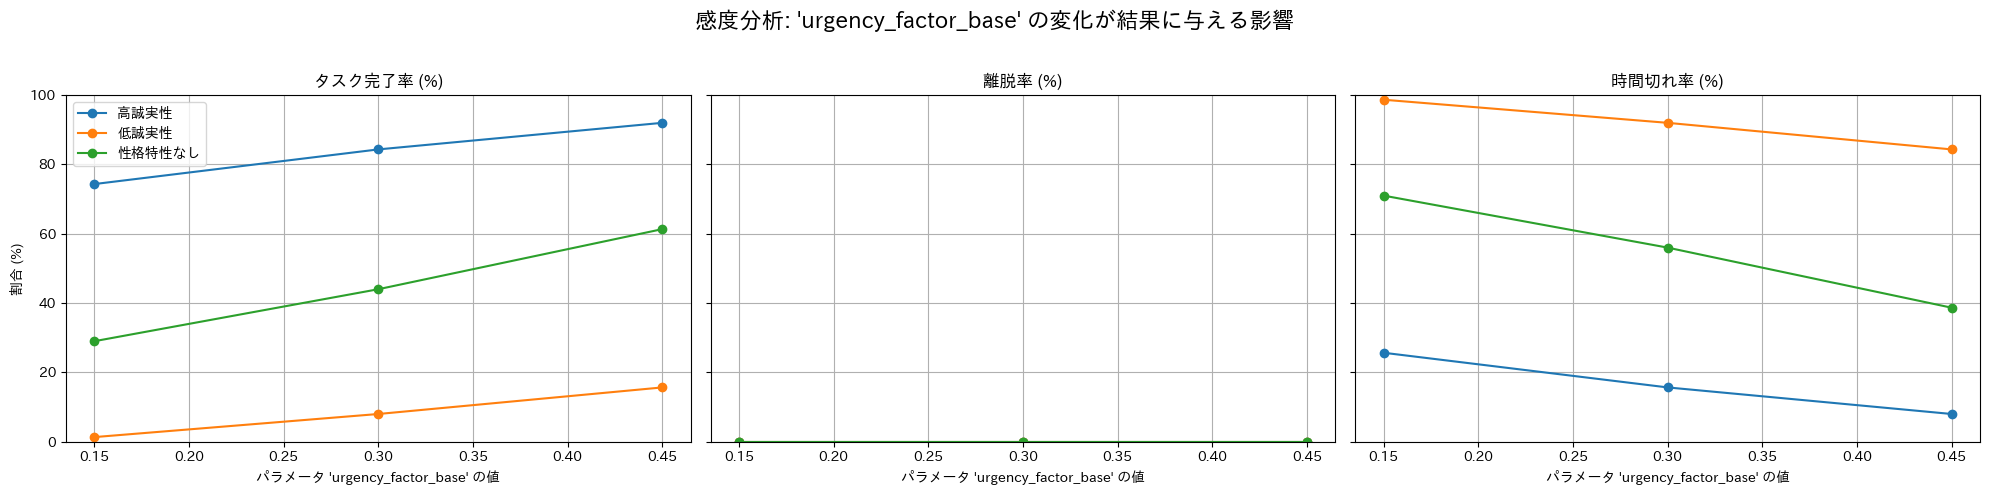

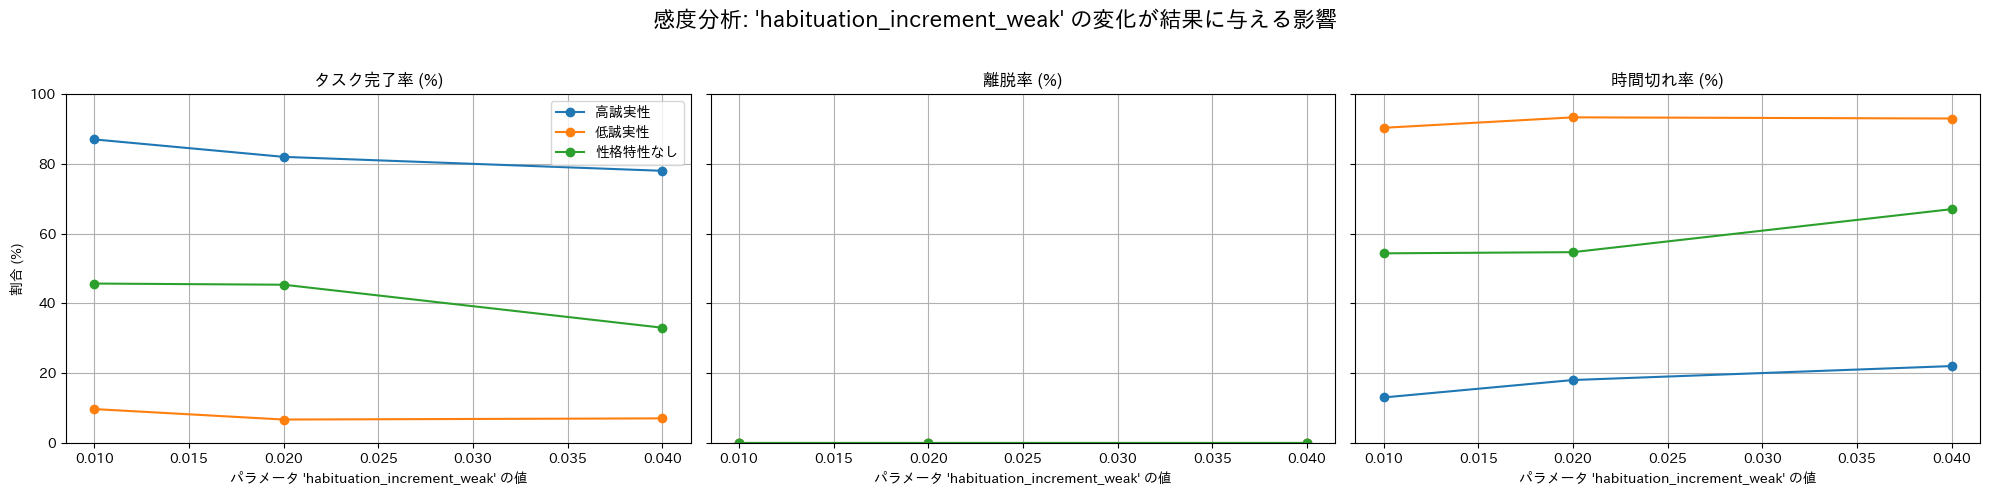

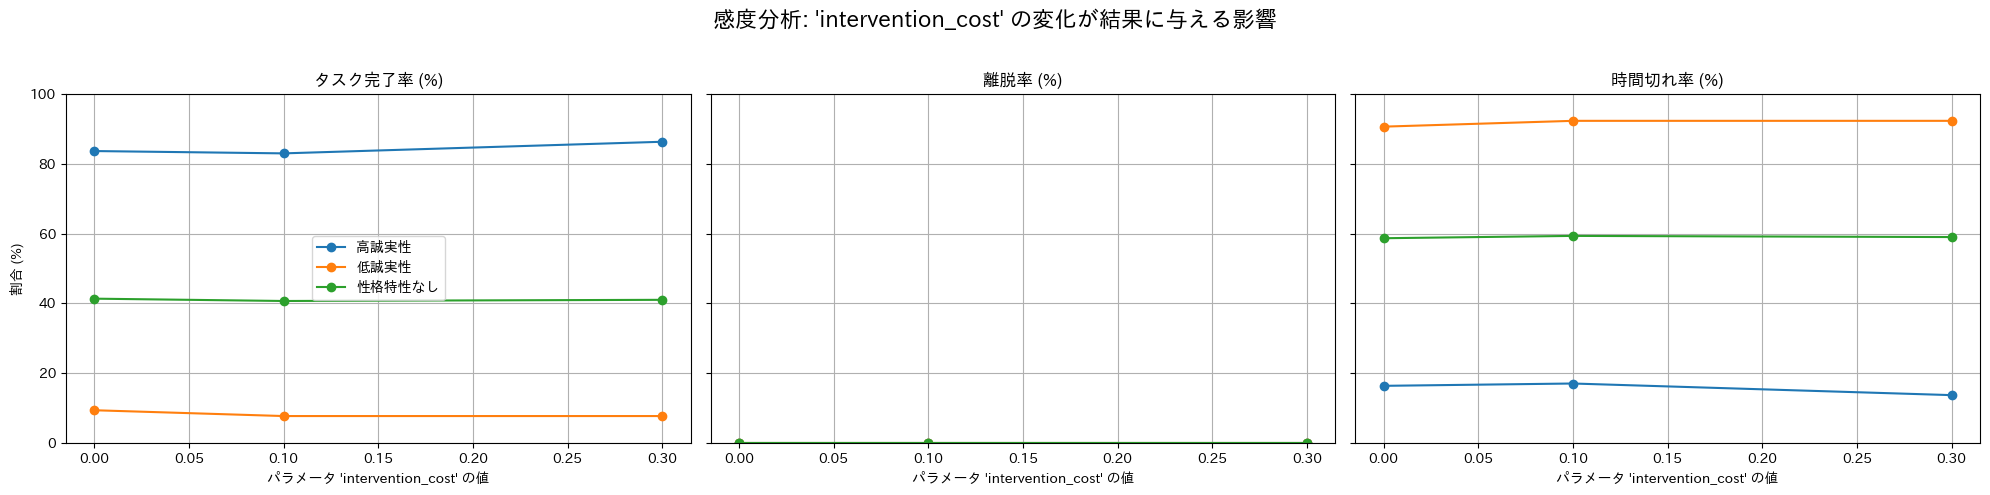

--- 感度分析（完了率・離脱率付き）を開始します ---

▼ 分析中のパラメータ: 'urgency_factor_base'
'urgency_factor_base' の分析完了。

▼ 分析中のパラメータ: 'habituation_increment_weak'
'habituation_increment_weak' の分析完了。

▼ 分析中のパラメータ: 'intervention_cost'
'intervention_cost' の分析完了。

--- 全ての分析が完了しました ---


NameError: name 'plot_rates_results' is not defined

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
# import japanize_matplotlib # 日本語表示が必要な場合は有効化してください

# -------------------------------------------------------------------
# ▼ STEP 0: ご自身のシミュレーションクラスの準備 ▼
# -------------------------------------------------------------------
# このセルを実行する前に、「class SimplifiedTaskJITAIEnv:」で始まる
# クラス定義のセルが実行済みであることを、改めてご確認ください。
# -------------------------------------------------------------------


# -------------------------------------------------------------------
# ▼ STEP 1: 感度分析の全体設定（変更なし） ▼
# -------------------------------------------------------------------
CO_SCORE_GROUPS = { "高誠実性": 0.8, "低誠実性": 0.2, "性格特性なし": 0.5 }
N_TRIALS = 300
BASELINE_PARAMS = {
    'n_actions': 3, 'max_episode_length': 90, 'total_task_work': 400.0,
    'delta_d_base': 0.02, 'epsilon_d_base': 0.05, 'D_threshold_base': 0.20,
    'd_increase_on_inaction_base': 0.002, 'co_effect_on_d_increase_inaction_multiplier': -0.5,
    'inaction_steps_threshold': 7, 'base_prob_start_action_base': 0.6,
    'urgency_factor_base': 0.3, 'mu_s_base': 4.1, 'rho1_base': 2.0, 'rho2_base': 5.0,
    'co_effect_on_delta_d_multiplier': 0.3, 'co_effect_on_epsilon_d_multiplier': 0.5,
    'co_effect_on_D_threshold_multiplier': 1.5, 'co_effect_on_base_prob_start_multiplier': 0.2,
    'co_effect_on_intervention_boost_multiplier': 0.1, 'co_effect_on_urgency_factor_multiplier': -0.4,
    'co_effect_on_mu_s_multiplier': 0.2, 'co_effect_on_rho1_multiplier': 0.1,
    'co_effect_on_rho2_multiplier': 0.1, 'init_d': 0.1,
    'chosen_obs_names': ['D', 'S', 'TP', 'CO', 'TR', 'T_parity', 'Habituation'],
    'n_version': 0, 's_noise_std_base': 0.0, 'co_effect_on_s_noise_std_multiplier': 0.0,
    'intervention_cost': 0.1, 'habituation_increment_weak': 0.02,
    'habituation_increment_strong': 0.05, 'habituation_decay': 0.01, 'render_mode': None,
    'weak_intervention_boost': 0.1, 'strong_to_weak_ratio': 2.5,
}
PARAMS_TO_TEST = {
    'urgency_factor_base': [
        BASELINE_PARAMS['urgency_factor_base'] * 0.5,
        BASELINE_PARAMS['urgency_factor_base'],
        BASELINE_PARAMS['urgency_factor_base'] * 1.5
    ],
    'habituation_increment_weak': [
        BASELINE_PARAMS['habituation_increment_weak'] * 0.5,
        BASELINE_PARAMS['habituation_increment_weak'],
        BASELINE_PARAMS['habituation_increment_weak'] * 2.0
    ],
    'intervention_cost': [
        0.0,                                      # コストなし
        BASELINE_PARAMS['intervention_cost'],     # 基準コスト
        BASELINE_PARAMS['intervention_cost'] * 3  # 高いコスト
    ]
}


# -------------------------------------------------------------------
# ▼ STEP 2: 感度分析の実行（結果の記録方法を修正） ▼
# -------------------------------------------------------------------
def run_sensitivity_analysis_with_rates():
    """感度分析を実行し、完了率や離脱率などの詳細な結果を返す関数"""
    results_data = {}
    print("--- 感度分析（完了率・離脱率付き）を開始します ---")

    for param_name, param_levels in PARAMS_TO_TEST.items():
        print(f"\n▼ 分析中のパラメータ: '{param_name}'")
        
        # このパラメータの分析結果を保存する辞書を初期化
        results_data[param_name] = {"levels": param_levels, "outputs": {group_name: [] for group_name in CO_SCORE_GROUPS}}

        for level in param_levels:
            for group_name, co_score in CO_SCORE_GROUPS.items():
                
                # ★★★【修正箇所】★★★
                # 試行ごとの「終了理由」を記録するリスト
                episode_outcomes = []
                
                for i in range(N_TRIALS):
                    params_for_run = BASELINE_PARAMS.copy()
                    params_for_run[param_name] = level
                    params_for_run['co_score'] = co_score
                    params_for_run['seed'] = i 
                    
                    weak_boost = params_for_run['weak_intervention_boost']
                    strong_boost = weak_boost * params_for_run['strong_to_weak_ratio']
                    params_for_run['intervention_boost_to_prob_start_base'] = [0.0, weak_boost, strong_boost]
                    del params_for_run['weak_intervention_boost']
                    del params_for_run['strong_to_weak_ratio']
                    
                    sim_instance = SimplifiedTaskJITAIEnv(**params_for_run)
                    obs, info = sim_instance.reset(seed=i)
                    terminated, truncated = False, False
                    
                    while not (terminated or truncated):
                       action = sim_instance.action_space.sample()
                       obs, reward, terminated, truncated, info = sim_instance.step(action)
                    
                    # ★★★【修正箇所】★★★
                    # エピソード終了理由を判定して記録
                    if info.get('task_completed', False) or info.get('task_completed_this_step', False):
                        episode_outcomes.append('completed')
                    elif info.get('disengaged', False):
                        episode_outcomes.append('disengaged')
                    elif truncated:
                        episode_outcomes.append('timeout')
                    else:
                        episode_outcomes.append('unknown') # その他の終了理由
                
                # ★★★【修正箇所】★★★
                # 記録した終了理由から、各率を計算
                total_trials = len(episode_outcomes)
                completion_rate = (episode_outcomes.count('completed') / total_trials) * 100
                disengagement_rate = (episode_outcomes.count('disengaged') / total_trials) * 100
                timeout_rate = (episode_outcomes.count('timeout') / total_trials) * 100
                
                # 計算した率を辞書として保存
                rates = {
                    'completion_rate': completion_rate,
                    'disengagement_rate': disengagement_rate,
                    'timeout_rate': timeout_rate
                }
                results_data[param_name]["outputs"][group_name].append(rates)
                
        print(f"'{param_name}' の分析完了。")

    print("\n--- 全ての分析が完了しました ---")
    return results_data


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
# import japanize_matplotlib # 日本語表示が必要な場合は有効化してください

# (STEP 0 と STEP 1 のコードは、前回のものと同じなので省略)
# ...

# (STEP 2 の run_sensitivity_analysis_with_rates 関数も同じなので省略)
# ...


# -------------------------------------------------------------------
# ▼ STEP 3: 結果の可視化（折れ線グラフに変更） ▼
# -------------------------------------------------------------------
def plot_rates_results_line(results_data):
    """完了率・離脱率などの結果を、個別の折れ線グラフで表示する関数"""
    print("\n--- 結果をグラフで表示します ---")

    # 分析したパラメータごとにループ
    for param_name, data in results_data.items():
        
        # 1つのパラメータに対して、3つのグラフを横に並べて表示
        fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
        fig.suptitle(f"感度分析: '{param_name}' の変化が結果に与える影響", fontsize=16)

        # 1. 完了率のグラフ
        ax1 = axes[0]
        for group_name in CO_SCORE_GROUPS.keys():
            rates = [d['completion_rate'] for d in data["outputs"][group_name]]
            ax1.plot(data["levels"], rates, marker='o', label=group_name)
        ax1.set_title("タスク完了率 (%)")
        ax1.set_xlabel(f"パラメータ '{param_name}' の値")
        ax1.set_ylabel("割合 (%)")
        ax1.grid(True)
        ax1.legend()

        # 2. 離脱率のグラフ
        ax2 = axes[1]
        for group_name in CO_SCORE_GROUPS.keys():
            rates = [d['disengagement_rate'] for d in data["outputs"][group_name]]
            ax2.plot(data["levels"], rates, marker='o', label=group_name)
        ax2.set_title("離脱率 (%)")
        ax2.set_xlabel(f"パラメータ '{param_name}' の値")
        ax2.grid(True)
        
        # 3. 時間切れ率のグラフ
        ax3 = axes[2]
        for group_name in CO_SCORE_GROUPS.keys():
            rates = [d['timeout_rate'] for d in data["outputs"][group_name]]
            ax3.plot(data["levels"], rates, marker='o', label=group_name)
        ax3.set_title("時間切れ率 (%)")
        ax3.set_xlabel(f"パラメータ '{param_name}' の値")
        ax3.grid(True)

        # Y軸の範囲を0-100%に統一
        for ax in axes:
            ax.set_ylim(0, 100)
            
        plt.tight_layout(rect=[0, 0, 1, 0.96]) # suptitleと重ならないように調整
        plt.show()

# -------------------------------------------------------------------
# ▼ メイン処理の実行 ▼
# -------------------------------------------------------------------
if __name__ == '__main__':
    # STEP 2の関数を呼び出す
    final_rates_results = run_sensitivity_analysis_with_rates()
    # 新しいプロット関数を呼び出す
    plot_rates_results_line(final_rates_results)


# -------------------------------------------------------------------
# ▼ メイン処理の実行 ▼
# -------------------------------------------------------------------
if __name__ == '__main__':
    final_rates_results = run_sensitivity_analysis_with_rates()
    plot_rates_results(final_rates_results)

--- 感度分析（完了率・離脱率付き）を開始します ---

▼ 分析中のパラメータ: 'urgency_factor_base'
'urgency_factor_base' の分析完了。

▼ 分析中のパラメータ: 'habituation_increment_weak'
'habituation_increment_weak' の分析完了。

▼ 分析中のパラメータ: 'intervention_cost'
'intervention_cost' の分析完了。

--- 全ての分析が完了しました ---

--- 結果をグラフで表示します ---


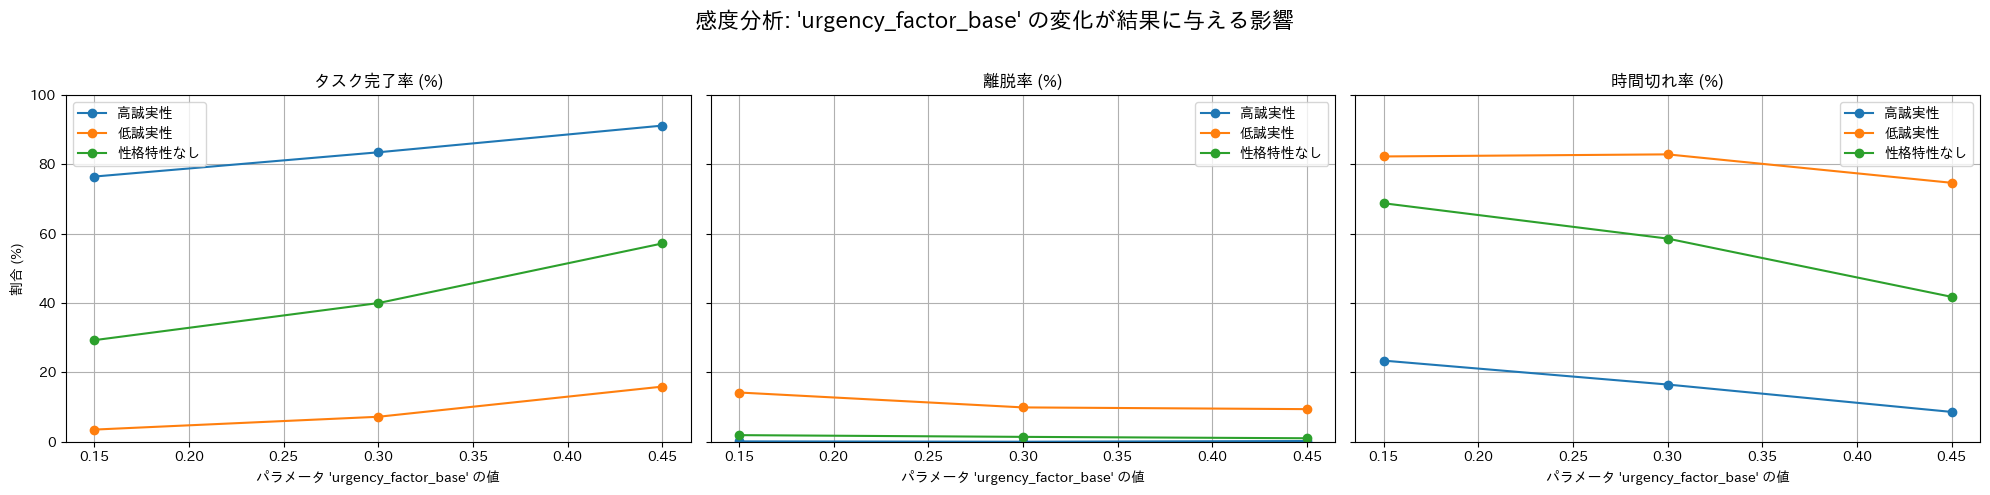

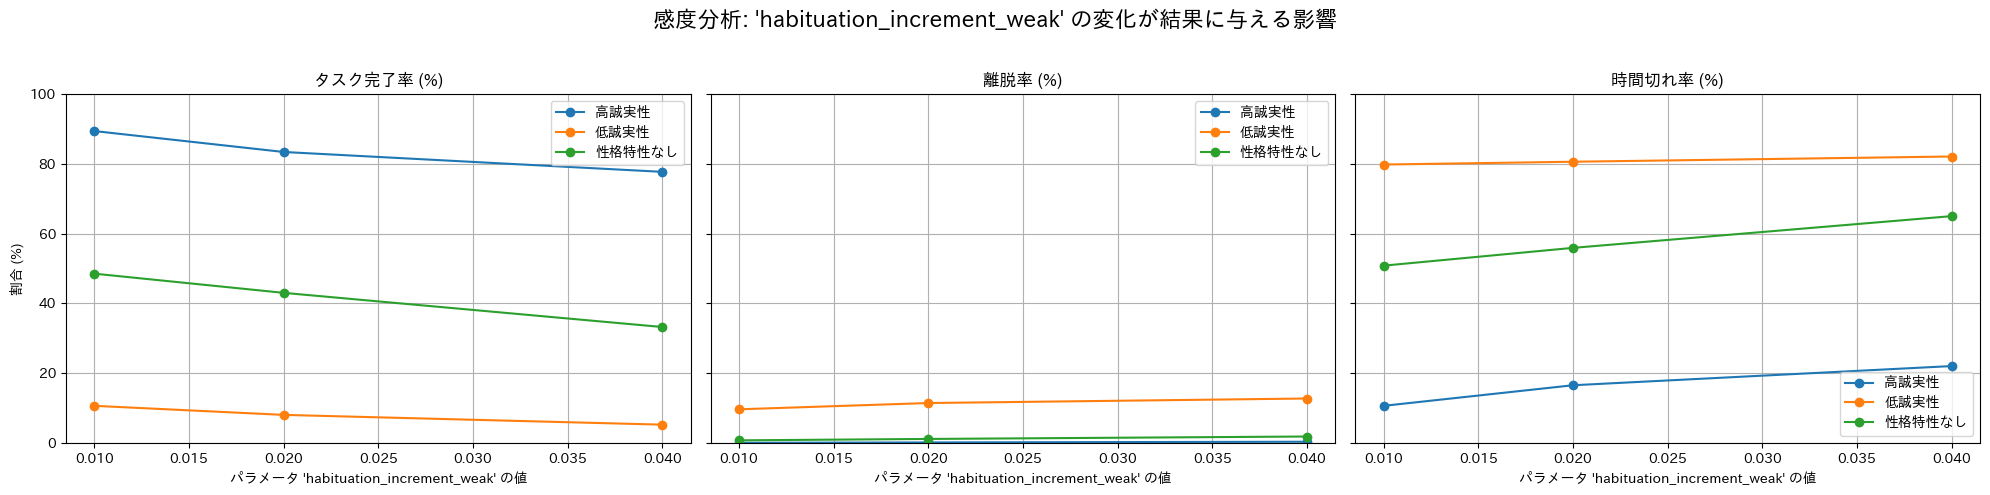

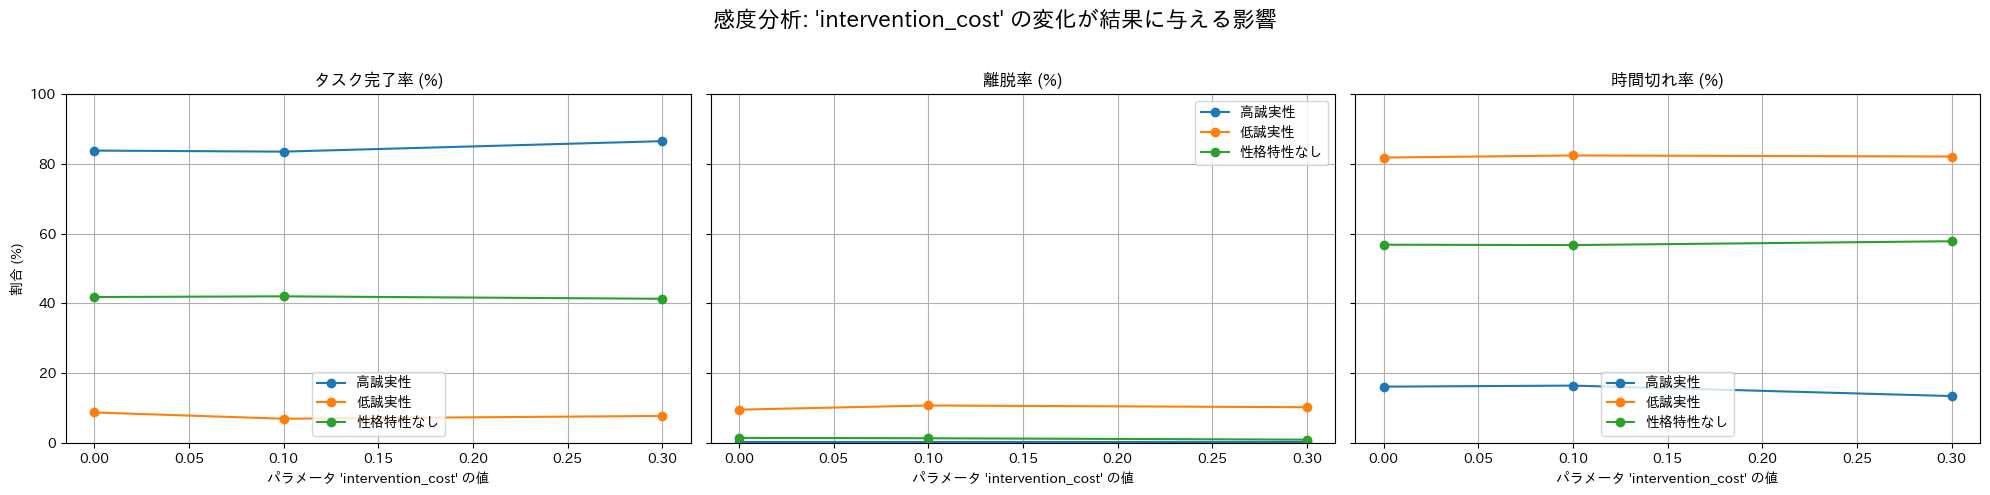

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
# import japanize_matplotlib # 日本語表示が必要な場合は有効化してください

# -------------------------------------------------------------------
# ▼ STEP 0: ご自身のシミュレーションクラスの準備 ▼
# -------------------------------------------------------------------
# このセルを実行する前に、「class SimplifiedTaskJITAIEnv:」で始まる
# クラス定義のセルが実行済みであることを、改めてご確認ください。
# -------------------------------------------------------------------


# -------------------------------------------------------------------
# ▼ STEP 1: 感度分析の全体設定 ▼
# -------------------------------------------------------------------

# 1-A. 比較グループの定義
CO_SCORE_GROUPS = {
    "高誠実性": 0.8,
    "低誠実性": 0.2,
    "性格特性なし": 0.5
}

# 1-B. 各条件下での試行回数
N_TRIALS = 1000

# 1-C. シミュレーションの基準となるパラメータ設定
# 【重要】ご自身のクラスの__init__メソッドの引数名とデフォルト値に準拠
BASELINE_PARAMS = {
    'n_actions': 3,
    'max_episode_length': 90,
    'total_task_work': 400.0,
    'delta_d_base': 0.02,
    'epsilon_d_base': 0.05,
    'D_threshold_base': 0.10,
    'd_increase_on_inaction_base': 0.01,
    'co_effect_on_d_increase_inaction_multiplier': -0.5,
    'inaction_steps_threshold': 3,
    'base_prob_start_action_base': 0.6,
    'urgency_factor_base': 0.3,
    'mu_s_base': 4.1,
    'rho1_base': 2.0,
    'rho2_base': 5.0,
    'co_effect_on_delta_d_multiplier': 0.3,
    'co_effect_on_epsilon_d_multiplier': 0.5,
    'co_effect_on_D_threshold_multiplier': 1.5,
    'co_effect_on_base_prob_start_multiplier': 0.2,
    'co_effect_on_intervention_boost_multiplier': 0.1,
    'co_effect_on_urgency_factor_multiplier': -0.4,
    'co_effect_on_mu_s_multiplier': 0.2,
    'co_effect_on_rho1_multiplier': 0.1,
    'co_effect_on_rho2_multiplier': 0.1,
    'chosen_obs_names': ['D', 'S', 'TP', 'CO', 'TR', 'T_parity', 'Habituation'],
    'n_version': 0,
    's_noise_std_base': 0.0,
    'co_effect_on_s_noise_std_multiplier': 0.0,
    'intervention_cost': 0.1,
    'habituation_increment_weak': 0.02,
    'habituation_increment_strong': 0.05,
    'habituation_decay': 0.01,
    'render_mode': None,
    # ★介入効果リストとリスク初期値を定義
    'intervention_boost_to_prob_start_base': [0.0, 0.1, 0.25],
    'init_d': 0.0,
}

# 1-D. 感度分析で変動させるパラメータと、その水準を定義
PARAMS_TO_TEST = {
    'urgency_factor_base': [
        BASELINE_PARAMS['urgency_factor_base'] * 0.5,
        BASELINE_PARAMS['urgency_factor_base'],
        BASELINE_PARAMS['urgency_factor_base'] * 1.5
    ],
    'habituation_increment_weak': [
        BASELINE_PARAMS['habituation_increment_weak'] * 0.5,
        BASELINE_PARAMS['habituation_increment_weak'],
        BASELINE_PARAMS['habituation_increment_weak'] * 2.0
    ],
    'intervention_cost': [
        0.0,
        BASELINE_PARAMS['intervention_cost'],
        BASELINE_PARAMS['intervention_cost'] * 3
    ]
}


# -------------------------------------------------------------------
# ▼ STEP 2: 感度分析の実行 ▼
# -------------------------------------------------------------------
def run_sensitivity_analysis_with_rates():
    """感度分析を実行し、完了率や離脱率などの詳細な結果を返す関数"""
    results_data = {}
    print("--- 感度分析（完了率・離脱率付き）を開始します ---")

    for param_name, param_levels in PARAMS_TO_TEST.items():
        print(f"\n▼ 分析中のパラメータ: '{param_name}'")
        
        results_data[param_name] = {"levels": param_levels, "outputs": {group_name: [] for group_name in CO_SCORE_GROUPS}}

        for level in param_levels:
            for group_name, co_score in CO_SCORE_GROUPS.items():
                
                episode_outcomes = []
                for i in range(N_TRIALS):
                    params_for_run = BASELINE_PARAMS.copy()
                    params_for_run[param_name] = level
                    params_for_run['co_score'] = co_score
                    params_for_run['seed'] = i 
                    
                    # このコードブロックは、`__init__`が要求しない一時的なキーを削除するためのものです。
                    # エラーを防ぐため、このままにしておいてください。
                    if 'weak_intervention_boost' in params_for_run and 'intervention_boost_to_prob_start_base' not in params_for_run:
                        weak_boost = params_for_run.get('weak_intervention_boost', BASELINE_PARAMS.get('weak_intervention_boost'))
                        strong_ratio = params_for_run.get('strong_to_weak_ratio', BASELINE_PARAMS.get('strong_to_weak_ratio'))
                        strong_boost = weak_boost * strong_ratio
                        params_for_run['intervention_boost_to_prob_start_base'] = [0.0, weak_boost, strong_boost]
                    
                    if 'weak_intervention_boost' in params_for_run:
                        del params_for_run['weak_intervention_boost']
                    if 'strong_to_weak_ratio' in params_for_run:
                        del params_for_run['strong_to_weak_ratio']
                    
                    sim_instance = SimplifiedTaskJITAIEnv(**params_for_run)
                    obs, info = sim_instance.reset(seed=i)
                    terminated, truncated = False, False
                    
                    while not (terminated or truncated):
                       action = sim_instance.action_space.sample()
                       obs, reward, terminated, truncated, info = sim_instance.step(action)
                    
                    if info.get('task_completed', False) or info.get('task_completed_this_step', False):
                        episode_outcomes.append('completed')
                    elif info.get('disengaged', False):
                        episode_outcomes.append('disengaged')
                    elif truncated:
                        episode_outcomes.append('timeout')
                    else:
                        episode_outcomes.append('unknown')
                
                total_trials = len(episode_outcomes)
                completion_rate = (episode_outcomes.count('completed') / total_trials) * 100 if total_trials > 0 else 0
                disengagement_rate = (episode_outcomes.count('disengaged') / total_trials) * 100 if total_trials > 0 else 0
                timeout_rate = (episode_outcomes.count('timeout') / total_trials) * 100 if total_trials > 0 else 0
                
                rates = {
                    'completion_rate': completion_rate,
                    'disengagement_rate': disengagement_rate,
                    'timeout_rate': timeout_rate
                }
                results_data[param_name]["outputs"][group_name].append(rates)
                
        print(f"'{param_name}' の分析完了。")

    print("\n--- 全ての分析が完了しました ---")
    return results_data


# -------------------------------------------------------------------
# ▼ STEP 3: 結果の可視化 ▼
# -------------------------------------------------------------------
def plot_rates_results_line(results_data):
    """完了率・離脱率などの結果を、個別の折れ線グラフで表示する関数"""
    print("\n--- 結果をグラフで表示します ---")
    
    for param_name, data in results_data.items():
        fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
        fig.suptitle(f"感度分析: '{param_name}' の変化が結果に与える影響", fontsize=16)

        metrics_to_plot = [('completion_rate', "タスク完了率 (%)"), 
                           ('disengagement_rate', "離脱率 (%)"), 
                           ('timeout_rate', "時間切れ率 (%)")]

        for i, (metric, title) in enumerate(metrics_to_plot):
            ax = axes[i]
            for group_name in CO_SCORE_GROUPS.keys():
                rates = [d[metric] for d in data["outputs"][group_name]]
                ax.plot(data["levels"], rates, marker='o', label=group_name)
            ax.set_title(title)
            ax.set_xlabel(f"パラメータ '{param_name}' の値")
            if i == 0:
                ax.set_ylabel("割合 (%)")
            ax.grid(True)
            ax.legend()
            ax.set_ylim(0, 100)
            
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

# -------------------------------------------------------------------
# ▼ メイン処理の実行 ▼
# -------------------------------------------------------------------
# このセルが実行された際に、上記の関数を呼び出す
final_rates_results = run_sensitivity_analysis_with_rates()
plot_rates_results_line(final_rates_results)

In [39]:
import numpy as np
import pandas as pd
import itertools
# import japanize_matplotlib # 必要に応じて有効化

# -------------------------------------------------------------------
# ▼ STEP 0: ご自身のシミュレーションクラスの準備 ▼
# -------------------------------------------------------------------
# このセルを実行する前に、「class SimplifiedTaskJITAIEnv:」で始まる
# クラス定義のセルが実行済みであることを、改めてご確認ください。
# -------------------------------------------------------------------


# -------------------------------------------------------------------
# ▼ STEP 1: キャリブレーションの全体設定 ▼
# -------------------------------------------------------------------

# 1-A. テスト対象のグループを「低誠実性」に固定
CO_SCORE_TO_TEST = 0.2

# 1-B. 各条件下での試行回数
N_TRIALS = 600

# 1-C. 調整したいパラメータと、その試行する水準を定義
# 調整したいパラメータと、その試行する水準を定義
# 調整したいパラメータと、その試行する水準を定義
# 調整したいパラメータと、その試行する水準を定義
# 調整したいパラメータと、その試行する水準を定義
PARAMS_TO_GRID_SEARCH = {
    'D_threshold_base': [0.10], # この上限値でテストを続ける
    'd_increase_on_inaction_base': [0.01,0.02,0.03,0.04, 0.05, 0.1] # ★ 前回と前々回の中間の、より細かい範囲を探索
}

# 1-D. その他のパラメータは基準値に固定
# (BASELINE_PARAMSは前回の感度分析コードのものを再利用)
BASELINE_PARAMS = {
    'n_actions': 3, 'max_episode_length': 90, 'total_task_work': 400.0,
    'delta_d_base': 0.02, 'epsilon_d_base': 0.05,
    # D_threshold_base と d_increase_on_inaction_base はループ内で上書きされる
    'co_effect_on_d_increase_inaction_multiplier': -0.5,
    'inaction_steps_threshold': 3, 'base_prob_start_action_base': 0.6,
    'urgency_factor_base': 0.3, 'mu_s_base': 4.1, 'rho1_base': 2.0, 'rho2_base': 5.0,
    'co_effect_on_delta_d_multiplier': 0.3, 'co_effect_on_epsilon_d_multiplier': 0.5,
    'co_effect_on_D_threshold_multiplier': 1.5, 'co_effect_on_base_prob_start_multiplier': 0.2,
    'co_effect_on_intervention_boost_multiplier': 0.1, 'co_effect_on_urgency_factor_multiplier': -0.4,
    'co_effect_on_mu_s_multiplier': 0.2, 'co_effect_on_rho1_multiplier': 0.1,
    'co_effect_on_rho2_multiplier': 0.1, 'init_d': 0.1,
    'chosen_obs_names': ['D', 'S', 'TP', 'CO', 'TR', 'T_parity', 'Habituation'],
    'n_version': 0, 's_noise_std_base': 0.0, 'co_effect_on_s_noise_std_multiplier': 0.0,
    'intervention_cost': 0.1, 'habituation_increment_weak': 0.02,
    'habituation_increment_strong': 0.05, 'habituation_decay': 0.01, 'render_mode': None,
    'intervention_boost_to_prob_start_base': [0.0, 0.1, 0.25],'init_d': 0.0,
}


# -------------------------------------------------------------------
# ▼ STEP 2: グリッドサーチの実行 ▼
# -------------------------------------------------------------------
def run_calibration_grid_search():
    """パラメータの組み合わせを試し、離脱率を計算する関数"""
    
    # 全てのパラメータの組み合わせを生成
    param_names = list(PARAMS_TO_GRID_SEARCH.keys())
    param_levels = list(PARAMS_TO_GRID_SEARCH.values())
    grid_combinations = list(itertools.product(*param_levels))
    
    # 結果を保存するリスト
    calibration_results = []
    
    print(f"--- キャリブレーションを開始します（全{len(grid_combinations)}通り） ---")

    for combo in grid_combinations:
        
        params_for_run = BASELINE_PARAMS.copy()
        
        # 現在の組み合わせのパラメータ値を設定
        param_combo_str = []
        for i, name in enumerate(param_names):
            params_for_run[name] = combo[i]
            param_combo_str.append(f"{name}={combo[i]:.3f}")
        
        print(f"テスト中: {', '.join(param_combo_str)}")

        episode_outcomes = []
        for i in range(N_TRIALS):
            # 常に同じ性格・乱数シードでテスト
            params_for_run['co_score'] = CO_SCORE_TO_TEST
            params_for_run['seed'] = i
            
            sim_instance = SimplifiedTaskJITAIEnv(**params_for_run)
            obs, info = sim_instance.reset(seed=i)
            terminated, truncated = False, False
            
            while not (terminated or truncated):
                action = sim_instance.action_space.sample()
                obs, reward, terminated, truncated, info = sim_instance.step(action)
                
            if info.get('disengaged', False):
                episode_outcomes.append('disengaged')
        
        # 離脱率を計算
        disengagement_rate = (episode_outcomes.count('disengaged') / N_TRIALS) * 100
        
        # 結果を保存
        result_row = {
            param_names[0]: combo[0],
            param_names[1]: combo[1],
            'disengagement_rate': disengagement_rate
        }
        calibration_results.append(result_row)
        
    print("\n--- キャリブレーションが完了しました ---")
    return calibration_results


# -------------------------------------------------------------------
# ▼ STEP 3: 結果を表形式で表示 ▼
# -------------------------------------------------------------------
def display_results_table(results_list):
    """結果を見やすいテーブル形式に整形して表示する関数"""
    if not results_list:
        print("結果がありません。")
        return
        
    df = pd.DataFrame(results_list)
    
    # ピボットテーブルを作成して、行と列にパラメータを配置
    param_row = list(PARAMS_TO_GRID_SEARCH.keys())[0] # 'D_threshold_base'
    param_col = list(PARAMS_TO_GRID_SEARCH.keys())[1] # 'd_increase_on_inaction_base'
    
    pivot_table = df.pivot_table(
        index=param_row, 
        columns=param_col, 
        values='disengagement_rate'
    )
    
    # 見やすいように整形
    pivot_table = pivot_table.style.format("{:.1f}%").background_gradient(cmap='viridis', vmin=0, vmax=100)
    
    print("\n【離脱率の結果（低誠実性グループ）】")
    display(pivot_table)
    print("\n目標：離脱率が20%〜50%程度になる組み合わせを探してください。")


# -------------------------------------------------------------------
# ▼ メイン処理の実行 ▼
# -------------------------------------------------------------------
if __name__ == '__main__':
    calibration_data = run_calibration_grid_search()
    display_results_table(calibration_data)

--- キャリブレーションを開始します（全6通り） ---
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.010
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.020
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.030
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.040
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.050
テスト中: D_threshold_base=0.100, d_increase_on_inaction_base=0.100

--- キャリブレーションが完了しました ---

【離脱率の結果（低誠実性グループ）】


d_increase_on_inaction_base,0.010000,0.020000,0.030000,0.040000,0.050000,0.100000
D_threshold_base,,,,,,
0.100000,11.5%,48.5%,73.5%,73.8%,86.8%,95.5%



目標：離脱率が20%〜50%程度になる組み合わせを探してください。
